In [1]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Dataset

df = pd.read_csv("../data/raw/StudentsPerformance.csv")

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Dataset Shape
print("\nDataset Shape:", df.shape)

# Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset Information
print("\nDataset Information:")
df.info()

First 5 Rows:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



Dataset Shape: (1000, 8)

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [3]:
# Create Target Variable

df['math_result'] = (df['math score'] >= 40).astype(int)

# Display target distribution
print("Target Variable Distribution:")
print(df['math_result'].value_counts())

# Display target labels
print("\nTarget Labels:")
print(df['math_result'].value_counts().rename(index={
    1: 'Pass',
    0: 'Fail'
}))

# Check dataset
display(df[['math score', 'math_result']].head(10))

Target Variable Distribution:
math_result
1    960
0     40
Name: count, dtype: int64

Target Labels:
math_result
Pass    960
Fail     40
Name: count, dtype: int64


,math score,math_result
0,72,1
1,69,1
2,90,1
3,47,1
4,76,1
5,71,1
6,88,1
7,40,1
8,64,1
9,38,0


In [4]:
# Separate Features and Target

X = df.drop(columns=['math score', 'math_result'])
y = df['math_result']

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Categorical Features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

Numerical Features:
['reading score', 'writing score']

Features Shape: (1000, 7)
Target Shape: (1000,)


In [5]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features Shape: (800, 7)
Testing Features Shape: (200, 7)

Training Target Distribution:
math_result
1    768
0     32
Name: count, dtype: int64

Testing Target Distribution:
math_result
1    192
0      8
Name: count, dtype: int64


In [6]:
# Create Preprocessing Pipelines

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [7]:
# Create Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression Pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Random Forest Pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ))
])

print("Both ML models created successfully!")

Both ML models created successfully!


In [8]:
# Train Models

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Logistic Regression training completed!")
print("Random Forest training completed!")

Logistic Regression training completed!
Random Forest training completed!


In [9]:
# Evaluate Both Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.945,0.9840,0.9583,0.971,0.9714
1,Random Forest,0.975,0.9845,0.9896,0.987,0.9421


In [10]:
# Detailed Classification Reports

for name, model in models.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Fail", "Pass"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

        Fail       0.38      0.62      0.48         8
        Pass       0.98      0.96      0.97       192

    accuracy                           0.94       200
   macro avg       0.68      0.79      0.72       200
weighted avg       0.96      0.94      0.95       200


Random Forest
              precision    recall  f1-score   support

        Fail       0.71      0.62      0.67         8
        Pass       0.98      0.99      0.99       192

    accuracy                           0.97       200
   macro avg       0.85      0.81      0.83       200
weighted avg       0.97      0.97      0.97       200



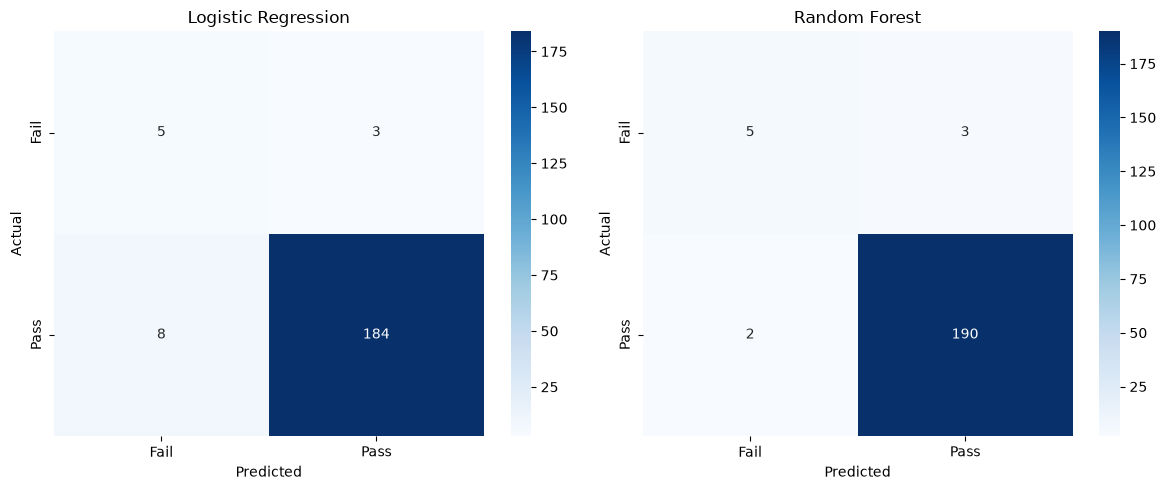

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Fail', 'Pass'],
        yticklabels=['Fail', 'Pass'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()

plt.savefig(
    '../reports/figures/confusion_matrix_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro',
    'fail_recall': make_scorer(recall_score, pos_label=0)
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'Macro F1': scores['test_f1_macro'].mean(),
        'Fail Recall': scores['test_fail_recall'].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,Fail Recall
0,Logistic Regression,0.9588,0.9489,0.8114,0.9381
1,Random Forest,0.9838,0.8777,0.8853,0.7619


In [13]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

# Save Logistic Regression
joblib.dump(
    logistic_model,
    '../models/logistic_regression_model.pkl'
)

# Save Random Forest
joblib.dump(
    random_forest_model,
    '../models/random_forest_model.pkl'
)

# Save selected model
joblib.dump(
    logistic_model,
    '../models/best_model.pkl'
)

# Save comparison results
cv_results_df.to_csv(
    '../reports/cross_validation_results.csv',
    index=False
)

print("Both models saved successfully!")
print("Selected Model: Logistic Regression")
print("Cross-validation results saved successfully!")

Both models saved successfully!
Selected Model: Logistic Regression
Cross-validation results saved successfully!


In [14]:
import os

print("Models folder:")
for file in os.listdir('../models'):
    print(" -", file)

print("\nReports folder:")
for file in os.listdir('../reports'):
    print(" -", file)

Models folder:
 - best_model.pkl
 - logistic_regression_model.pkl
 - random_forest_model.pkl

Reports folder:
 - cross_validation_results.csv
 - figures


In [16]:
import pandas as pd
import numpy as np
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


# ==========================================
# 1. PROJECT PATHS
# ==========================================

BASE_DIR = os.path.dirname(os.getcwd())

DATA_PATH = os.path.join(
    BASE_DIR, "data", "raw", "StudentsPerformance.csv"
)

MODEL_DIR = os.path.join(BASE_DIR, "models")

print("Project directory:", BASE_DIR)


# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


# ==========================================
# 3. CREATE TARGET VARIABLE
# ==========================================

df["math_result"] = (df["math score"] >= 40).astype(int)

X = df.drop(columns=["math score", "math_result"])
y = df["math_result"]


# ==========================================
# 4. IDENTIFY FEATURE TYPES
# ==========================================

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()


# ==========================================
# 5. TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ==========================================
# 6. DATA PREPROCESSING
# ==========================================

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])


# ==========================================
# 7. CREATE MODELS
# ==========================================

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])


# ==========================================
# 8. TRAIN MODELS
# ==========================================

print("\nTraining Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)


# ==========================================
# 9. SAVE MODELS
# ==========================================

os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(
    logistic_model,
    os.path.join(MODEL_DIR, "logistic_regression_model.pkl")
)

joblib.dump(
    random_forest_model,
    os.path.join(MODEL_DIR, "random_forest_model.pkl")
)

joblib.dump(
    logistic_model,
    os.path.join(MODEL_DIR, "best_model.pkl")
)


# ==========================================
# 10. FINAL OUTPUT
# ==========================================

print("\n" + "=" * 45)
print("MODEL TRAINING COMPLETED SUCCESSFULLY!")
print("=" * 45)

print("Selected Model: Logistic Regression")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Models saved in:", MODEL_DIR)

Project directory: c:\Users\Balaji\Downloads\Student-Performance-Prediction
Dataset loaded successfully!
Dataset shape: (1000, 8)

Training Logistic Regression...
Training Random Forest...

MODEL TRAINING COMPLETED SUCCESSFULLY!
Selected Model: Logistic Regression
Training Records: 800
Testing Records: 200
Models saved in: c:\Users\Balaji\Downloads\Student-Performance-Prediction\models
